# 04. Feature Extraction Baseline

## 0. 실험 목적

ImageNet 사전학습 ResNet18의 특징 추출 능력을 활용하여
8개 행동 클래스를 분류하는 Feature Extraction 기준선을 구축한다.

- 사전학습된 백본 파라미터 동결
- 백본 BatchNorm 이동 통계 고정
- 새로운 FC Layer만 학습
- Scratch와 동일한 데이터 분할 및 전처리 적용
- Validation Macro F1 기준 최적 모델 선정
- Scratch 대비 분류 성능, 과적합 및 학습 효율 비교

## 1. 라이브러리 및 공통 모듈 Import

In [2]:
import sys
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import resnet18, ResNet18_Weights

# 프로젝트 루트 경로 설정
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
# 전처리
from src.preprocessing import (
    set_seed,
    get_dataloaders,
    SEED,
    IMAGE_SIZE,
    BATCH_SIZE,
    NUM_CLASSES,
    MEAN,
    STD,
)

# 학습
from src.training import (
    fit,
    save_training_results,
)

# 평가
from src.evaluation import (
    CLASS_NAMES,
    load_best_model,
    evaluate_model,
    analyze_class_performance,
    save_predictions,
    save_evaluation_results,
)

# 시각화
from src.visualization import (
    plot_learning_curves,
    plot_class_metrics,
    plot_confusion_matrix,
)

In [4]:
print("Project Root:", PROJECT_ROOT)
print("PyTorch Version:", torch.__version__)
print("CUDA Version:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n공통 전처리 설정")
print("Seed:", SEED)
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)
print("Mean:", MEAN)
print("Std:", STD)

print("\n공통 모듈 Import 완료")

Project Root: c:\Users\yunha\human-action-classification
PyTorch Version: 2.10.0+cu128
CUDA Version: 12.8
CUDA Available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU

공통 전처리 설정
Seed: 42
Image Size: 224
Batch Size: 32
Number of Classes: 8
Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)

공통 모듈 Import 완료


## 2. 실험 설정 및 경로 정의

Scratch 기준선과 동일한 데이터 및 학습 조건을 유지하고,
ImageNet 사전학습 가중치와 백본 동결을 적용한다.

공통 조건에서 학습 전략에 따른 분류 성능,
수렴 속도, 과적합 및 학습 효율의 차이를 비교한다.

학습률과 Epoch 등의 최적화는 이후 기본 튜닝 단계에서 수행한다.

In [5]:
EXPERIMENT_NAME = "feature_extraction_baseline"

EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
FREEZE_BACKBONE_BN = True

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

set_seed(SEED)

In [6]:
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
RESULT_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = PROJECT_ROOT / "figures"

for directory in [OUTPUT_DIR, RESULT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / f"{EXPERIMENT_NAME}_best.pth"

In [7]:
print("Experiment:", EXPERIMENT_NAME)
print("Model: ResNet18")
print("Pretrained Weights:", WEIGHTS)
print("Training Strategy: Feature Extraction")
print("Freeze Backbone BN:", FREEZE_BACKBONE_BN)

print("\n[Training Configuration]")
print("Optimizer: Adam")
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Seed:", SEED)
print("Device:", DEVICE)

print("\n[Paths]")
print("Data Directory:", DATA_DIR)
print("Checkpoint Path:", CHECKPOINT_PATH)
print("Result Directory:", RESULT_DIR)
print("Figure Directory:", FIGURE_DIR)

Experiment: feature_extraction_baseline
Model: ResNet18
Pretrained Weights: ResNet18_Weights.IMAGENET1K_V1
Training Strategy: Feature Extraction
Freeze Backbone BN: True

[Training Configuration]
Optimizer: Adam
Learning Rate: 0.001
Weight Decay: 0.0
Epochs: 30
Batch Size: 32
Seed: 42
Device: cuda

[Paths]
Data Directory: c:\Users\yunha\human-action-classification\data
Checkpoint Path: c:\Users\yunha\human-action-classification\outputs\feature_extraction_baseline_best.pth
Result Directory: c:\Users\yunha\human-action-classification\results
Figure Directory: c:\Users\yunha\human-action-classification\figures


## 3. DataLoader 구성

공통 전처리 모듈을 활용하여 Train, Validation, Test DataLoader를 구성한다.

- Scratch 기준선과 동일한 데이터 분할 및 전처리 유지
- Train에만 Shuffle 적용
- 입력 이미지 크기 및 Tensor Shape 확인
- 초기 기준선에서는 데이터 증강 미적용
- Test는 최종 모델 확정 전까지 평가에 사용하지 않음

In [8]:
import inspect

print(inspect.signature(get_dataloaders))

(data_dir=WindowsPath('C:/Users/yunha/human-action-classification/data'), batch_size=32, seed=42)


In [9]:
set_seed(SEED)

train_loader, val_loader, test_loader = get_dataloaders()

In [10]:
loader_info = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [
        len(train_loader.dataset),
        len(val_loader.dataset),
        len(test_loader.dataset),
    ],
    "Batches": [
        len(train_loader),
        len(val_loader),
        len(test_loader),
    ],
    "Batch Size": [
        train_loader.batch_size,
        val_loader.batch_size,
        test_loader.batch_size,
    ],
})

display(loader_info)

,Split,Images,Batches,Batch Size
0,Train,640,20,32
1,Validation,160,5,32
2,Test,1231,39,32


In [11]:
images, labels = next(iter(val_loader))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)
print("Image Dtype:", images.dtype)
print("Label Dtype:", labels.dtype)

Image Shape: torch.Size([32, 3, 224, 224])
Label Shape: torch.Size([32])
Image Dtype: torch.float32
Label Dtype: torch.int64


## 4. 사전학습 모델 생성 및 백본 동결

ImageNet 사전학습 ResNet18을 불러오고 기존 파라미터를 동결한다.

기존 FC Layer를 8개 행동 클래스에 맞는 새로운 분류기로
교체하여 해당 분류기만 학습하도록 구성한다.

- ImageNet 사전학습 가중치 사용
- 백본 파라미터 동결
- FC Layer 교체
- 학습 가능 파라미터 수 확인
- 모델 출력 Tensor Shape 검증

In [12]:
set_seed(SEED)

model = resnet18(weights=WEIGHTS)

print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [13]:
# 기존 모델의 모든 파라미터 동결
for param in model.parameters():
    param.requires_grad = False

# 기존 FC Layer의 입력 특징 수 확인
in_features = model.fc.in_features

# 새로운 분류기로 교체
model.fc = nn.Linear(in_features, NUM_CLASSES)

# GPU로 이동
model = model.to(DEVICE)

print(model.fc)

Linear(in_features=512, out_features=8, bias=True)


In [14]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters: {frozen_params:,}")
print(f"Trainable Ratio: {trainable_params / total_params:.4%}")

Total Parameters: 11,180,616
Trainable Parameters: 4,104
Frozen Parameters: 11,176,512
Trainable Ratio: 0.0367%


In [15]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

fc.weight torch.Size([8, 512])
fc.bias torch.Size([8])


In [16]:
model.eval()

images, labels = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    logits = model(images)

print("Input Shape:", images.shape)
print("Output Shape:", logits.shape)
print("Label Shape:", labels.shape)

assert logits.shape == (images.size(0), NUM_CLASSES)
assert trainable_params == 4104

print("\n모델 구성 검증 완료")

Input Shape: torch.Size([32, 3, 224, 224])
Output Shape: torch.Size([32, 8])
Label Shape: torch.Size([32])

모델 구성 검증 완료


## 5. Loss 및 Optimizer 설정

Scratch 기준선과 동일하게 CrossEntropyLoss와 Adam을 사용한다.

Feature Extraction에서는 백본 파라미터가 동결되어 있으므로
학습 가능한 FC Layer의 파라미터만 Optimizer에 전달한다.

- Loss: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Weight Decay: 0
- 학습 대상: FC Layer

In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

In [19]:
optimizer_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

print("Loss Function:", criterion)
print("Optimizer:", type(optimizer).__name__)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Weight Decay:", optimizer.param_groups[0]["weight_decay"])

print(f"\nTrainable Parameters: {trainable_params:,}")
print(f"Optimizer Parameters: {optimizer_params:,}")

assert optimizer_params == trainable_params == 4104

assert all(
    p.requires_grad
    for group in optimizer.param_groups
    for p in group["params"]
)

print("\nLoss 및 Optimizer 설정 검증 완료")

Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Weight Decay: 0.0

Trainable Parameters: 4,104
Optimizer Parameters: 4,104

Loss 및 Optimizer 설정 검증 완료


## 6. 학습 및 결과 저장

공통 학습 함수 fit()을 활용하여 Feature Extraction 기준선 모델을 학습한다.

- 30 Epoch 학습
- FC Layer 파라미터만 업데이트
- 백본 BatchNorm 이동 통계 고정
- Epoch별 Train/Validation Loss, Accuracy, Macro F1 기록
- 최대 Validation Macro F1 기준 Checkpoint 저장
- 전체 학습 시간 측정
- 실험 설정 및 학습 결과 저장

In [20]:
set_seed(SEED)

history_df, total_training_time = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    epochs=EPOCHS,
    checkpoint_path=CHECKPOINT_PATH,
    freeze_backbone_bn=FREEZE_BACKBONE_BN
)

Epoch [01/30] | Train Loss: 1.7227 | Train Acc: 0.4250 | Train F1: 0.4245 | Val Loss: 1.2614 | Val Acc: 0.7188 | Val F1: 0.7012 | Time: 2.75s | Best Model Saved
Epoch [02/30] | Train Loss: 0.9062 | Train Acc: 0.8406 | Train F1: 0.8386 | Val Loss: 0.8386 | Val Acc: 0.7750 | Val F1: 0.7605 | Time: 2.38s | Best Model Saved
Epoch [03/30] | Train Loss: 0.6037 | Train Acc: 0.8734 | Train F1: 0.8727 | Val Loss: 0.6682 | Val Acc: 0.8438 | Val F1: 0.8427 | Time: 2.32s | Best Model Saved
Epoch [04/30] | Train Loss: 0.4530 | Train Acc: 0.9156 | Train F1: 0.9161 | Val Loss: 0.6151 | Val Acc: 0.8375 | Val F1: 0.8294 | Time: 2.33s
Epoch [05/30] | Train Loss: 0.3783 | Train Acc: 0.9297 | Train F1: 0.9296 | Val Loss: 0.5465 | Val Acc: 0.8500 | Val F1: 0.8466 | Time: 2.32s | Best Model Saved
Epoch [06/30] | Train Loss: 0.3306 | Train Acc: 0.9406 | Train F1: 0.9405 | Val Loss: 0.5245 | Val Acc: 0.8500 | Val F1: 0.8469 | Time: 2.35s | Best Model Saved
Epoch [07/30] | Train Loss: 0.2888 | Train Acc: 0.945

In [21]:
display(history_df.head())
display(history_df.tail())

print(f"Total Training Time: {total_training_time:.2f} seconds")
print(f"Average Epoch Time: {total_training_time / EPOCHS:.2f} seconds")
print("Checkpoint Saved:", CHECKPOINT_PATH.exists())

,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
0,1,1.722714,0.425000,0.424457,1.261395,0.71875,0.701161,2.751805
1,2,0.906154,0.840625,0.838578,0.838640,0.77500,0.760463,2.377682
2,3,0.603687,0.873437,0.872712,0.668226,0.84375,0.842666,2.317821
3,4,0.453048,0.915625,0.916127,0.615115,0.83750,0.829386,2.329478
4,5,0.378300,0.929688,0.929570,0.546460,0.85000,0.846637,2.319846


,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
25,26,0.081501,0.992188,0.992177,0.402627,0.87500,0.869258,2.553167
26,27,0.077924,0.996875,0.996884,0.439585,0.86875,0.862990,2.548056
27,28,0.076807,0.993750,0.993750,0.402430,0.86875,0.862057,2.527069
28,29,0.071427,0.998437,0.998437,0.401448,0.87500,0.868979,2.527420
29,30,0.067814,0.998437,0.998437,0.406180,0.86875,0.861944,2.539354


Total Training Time: 73.02 seconds
Average Epoch Time: 2.43 seconds
Checkpoint Saved: True


In [24]:
best_idx = history_df["val_f1"].idxmax()
best_epoch_result = history_df.loc[[best_idx]]

display(best_epoch_result)

,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
16,17,0.130011,0.98125,0.981359,0.408662,0.88125,0.876476,2.335211


In [26]:
print(inspect.getsource(save_training_results))

def save_training_results(
    history_df,
    total_training_time,
    experiment_config,
    model,
    device,
    result_dir
):
    result_dir = Path(result_dir)
    result_dir.mkdir(parents=True, exist_ok=True)

    experiment_name = experiment_config["experiment_name"]

    # Epoch별 학습 기록 저장
    history_path = (
        result_dir / f"{experiment_name}_history.csv"
    )

    history_df.to_csv(history_path, index=False)

    # 최적 Epoch 추출
    best_result = history_df.loc[
        history_df["val_f1"].idxmax()
    ]

    # 파라미터 수 계산
    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # 실험 설정 및 주요 결과 요약
    summary = {
        **experiment_config,

        "total_params": total_params,
        "trainable_params": trainable_params,

        "best_epoch": int(best_result["epoch"]),
        "best_train_loss": best_result["train_loss"],
      

In [28]:
print(f"Total Training Time: {total_training_time:.2f} seconds")
print(f"Average Epoch Time: {total_training_time / EPOCHS:.2f} seconds")

Total Training Time: 73.02 seconds
Average Epoch Time: 2.43 seconds


In [29]:
scratch_summary_df = pd.read_csv(
    RESULT_DIR / "scratch_baseline_summary.csv"
)

display(scratch_summary_df.T)

,0
experiment_name,scratch_baseline
model,resnet18
training_strategy,scratch
pretrained_weights,NaN
train_samples,640
val_samples,160
num_classes,8
image_size,224
batch_size,32
augmentation,False


In [30]:
experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "model_name": "ResNet18",
    "training_strategy": "feature_extraction",
    "pretrained_weights": WEIGHTS.name,
    "trainable_layers": "fc",
    "freeze_backbone_bn": FREEZE_BACKBONE_BN,
    "optimizer": type(optimizer).__name__,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss_function": type(criterion).__name__,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "scheduler": "None",
    "augmentation": "None",
    "checkpoint_metric": "val_f1",
}

In [31]:
summary_df = save_training_results(
    history_df=history_df,
    total_training_time=total_training_time,
    experiment_config=experiment_config,
    model=model,
    device=DEVICE,
    result_dir=RESULT_DIR
)

display(summary_df.T)

History Saved: c:\Users\yunha\human-action-classification\results\feature_extraction_baseline_history.csv
Summary Saved: c:\Users\yunha\human-action-classification\results\feature_extraction_baseline_summary.csv


,0
experiment_name,feature_extraction_baseline
model_name,ResNet18
training_strategy,feature_extraction
pretrained_weights,IMAGENET1K_V1
trainable_layers,fc
freeze_backbone_bn,True
optimizer,Adam
learning_rate,0.001
weight_decay,0.0
loss_function,CrossEntropyLoss


In [32]:
history_path = RESULT_DIR / f"{EXPERIMENT_NAME}_history.csv"
summary_path = RESULT_DIR / f"{EXPERIMENT_NAME}_summary.csv"

print("Checkpoint Saved:", CHECKPOINT_PATH.exists())
print("History Saved:", history_path.exists())
print("Summary Saved:", summary_path.exists())

Checkpoint Saved: True
History Saved: True
Summary Saved: True


## 7. 최적 모델 평가 및 시각화

Validation Macro F1이 가장 높은 Epoch의 Checkpoint를 불러와
Validation 데이터에 대한 상세 평가를 수행한다.

- 최적 Checkpoint 로딩 및 성능 재현
- Accuracy, Macro Precision, Recall, F1-score 계산
- 클래스별 분류 성능 분석
- Confusion Matrix 및 주요 혼동 클래스 확인
- 이미지별 예측 결과 저장
- 학습 곡선 및 평가 결과 시각화

Test 데이터는 최종 모델 확정 전까지 평가에 사용하지 않는다.

In [33]:
best_model, checkpoint = load_best_model(
    model=model,
    checkpoint_path=CHECKPOINT_PATH,
    device=DEVICE
)

best_epoch = int(best_epoch_result["epoch"].iloc[0])

print("Best Epoch:", best_epoch)
print("Checkpoint Path:", CHECKPOINT_PATH)

===== Best Checkpoint Loaded =====
Best Epoch: 17
Validation Loss: 0.4087
Validation Accuracy: 0.8812
Validation Macro F1: 0.8765
Best Epoch: 17
Checkpoint Path: c:\Users\yunha\human-action-classification\outputs\feature_extraction_baseline_best.pth


In [34]:
evaluation = evaluate_model(
    model=best_model,
    dataloader=val_loader,
    criterion=criterion,
    device=DEVICE
)

display(pd.DataFrame([evaluation["metrics"]]))

,loss,accuracy,macro_precision,macro_recall,macro_f1
0,0.408662,0.88125,0.888939,0.88125,0.876476


In [35]:
class_analysis = analyze_class_performance(
    y_true=evaluation["y_true"],
    y_pred=evaluation["y_pred"],
    class_names=CLASS_NAMES
)

display(class_analysis["report_df"])

,precision,recall,f1-score,support
Climbing,0.909091,1.00000,0.952381,20.00000
Jumping,0.818182,0.90000,0.857143,20.00000
Riding Bike,0.869565,1.00000,0.930233,20.00000
Riding Horse,0.947368,0.90000,0.923077,20.00000
Rowing Boat,1.000000,0.95000,0.974359,20.00000
Running,0.923077,0.60000,0.727273,20.00000
Shooting Arrow,0.769231,1.00000,0.869565,20.00000
Throwing Frisbee,0.875000,0.70000,0.777778,20.00000
accuracy,0.881250,0.88125,0.881250,0.88125
macro avg,0.888939,0.88125,0.876476,160.00000


In [36]:
display(class_analysis["cm_df"])

display(class_analysis["confusion_pairs_df"])

,Climbing,Jumping,Riding Bike,Riding Horse,Rowing Boat,Running,Shooting Arrow,Throwing Frisbee
Climbing,20,0,0,0,0,0,0,0
Jumping,1,18,0,0,0,0,1,0
Riding Bike,0,0,20,0,0,0,0,0
Riding Horse,0,0,2,18,0,0,0,0
Rowing Boat,0,1,0,0,19,0,0,0
Running,1,2,1,1,0,12,1,2
Shooting Arrow,0,0,0,0,0,0,20,0
Throwing Frisbee,0,1,0,0,0,1,4,14


,true_class,predicted_class,count
0,Throwing Frisbee,Shooting Arrow,4
1,Running,Jumping,2
2,Running,Throwing Frisbee,2
3,Riding Horse,Riding Bike,2
4,Jumping,Climbing,1
5,Running,Climbing,1
6,Rowing Boat,Jumping,1
7,Jumping,Shooting Arrow,1
8,Running,Riding Bike,1
9,Running,Shooting Arrow,1


In [37]:
predictions_df = save_predictions(
    evaluation=evaluation,
    metadata_df=val_loader.dataset.df,
    dataloader=val_loader,
    experiment_name=EXPERIMENT_NAME,
    result_dir=RESULT_DIR
)

Predictions Saved: c:\Users\yunha\human-action-classification\results\feature_extraction_baseline_predictions.csv


In [38]:
predictions_df = pd.read_csv(
    RESULT_DIR / f"{EXPERIMENT_NAME}_predictions.csv"
)

display(predictions_df.head())

print("Total Images:", len(predictions_df))
print("Correct:", predictions_df["is_correct"].sum())
print("Incorrect:", (~predictions_df["is_correct"]).sum())

,image_id,image_path,split,target_id,class_name,class_name_ko,source_filename,original_split,group_id,width,...,confidence,is_correct,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7
0,s40_0216b979b86639cf5693,images/val/s40_0216b979b86639cf5693.jpg,val,5,running,달리기,running_043.jpg,train,group_s40_0216b979b86639cf5693,903,...,0.590368,True,0.001567,0.123468,0.000236,0.060148,1.968835e-02,0.590368,0.000200,2.043248e-01
1,s40_029af1e3d7b9729f517c,images/val/s40_029af1e3d7b9729f517c.jpg,val,7,throwing_frisby,프리스비 던지기,throwing_frisby_138.jpg,train,group_s40_029af1e3d7b9729f517c,200,...,0.637882,False,0.003445,0.039198,0.002893,0.001970,5.461953e-04,0.637882,0.020754,2.933132e-01
2,s40_02d39f1725b5d618f932,images/val/s40_02d39f1725b5d618f932.jpg,val,2,riding_a_bike,자전거 타기,riding_a_bike_030.jpg,train,group_s40_02d39f1725b5d618f932,300,...,0.999889,True,0.000003,0.000003,0.999889,0.000004,8.606052e-07,0.000097,0.000003,1.100430e-07
3,s40_0318ccfcfa1ee7a6bd3a,images/val/s40_0318ccfcfa1ee7a6bd3a.jpg,val,0,climbing,등반,climbing_092.jpg,train,group_s40_0318ccfcfa1ee7a6bd3a,400,...,0.995337,True,0.995337,0.002207,0.000258,0.000044,7.492360e-05,0.001787,0.000255,3.765671e-05
4,s40_036fd8dc9a335330714a,images/val/s40_036fd8dc9a335330714a.jpg,val,6,shooting_an_arrow,활쏘기,shooting_an_arrow_174.jpg,train,group_s40_036fd8dc9a335330714a,300,...,0.964164,True,0.008572,0.019490,0.000089,0.004493,6.676235e-04,0.000964,0.964164,1.560552e-03


Total Images: 160
Correct: 141
Incorrect: 19


In [39]:
save_evaluation_results(
    evaluation=evaluation,
    class_analysis=class_analysis,
    experiment_name=EXPERIMENT_NAME,
    epoch=best_epoch,
    result_dir=RESULT_DIR,
    split="validation"
)

Evaluation Results Saved


,experiment_name,split,epoch,loss,accuracy,macro_precision,macro_recall,macro_f1
0,feature_extraction_baseline,validation,17,0.408662,0.88125,0.888939,0.88125,0.876476


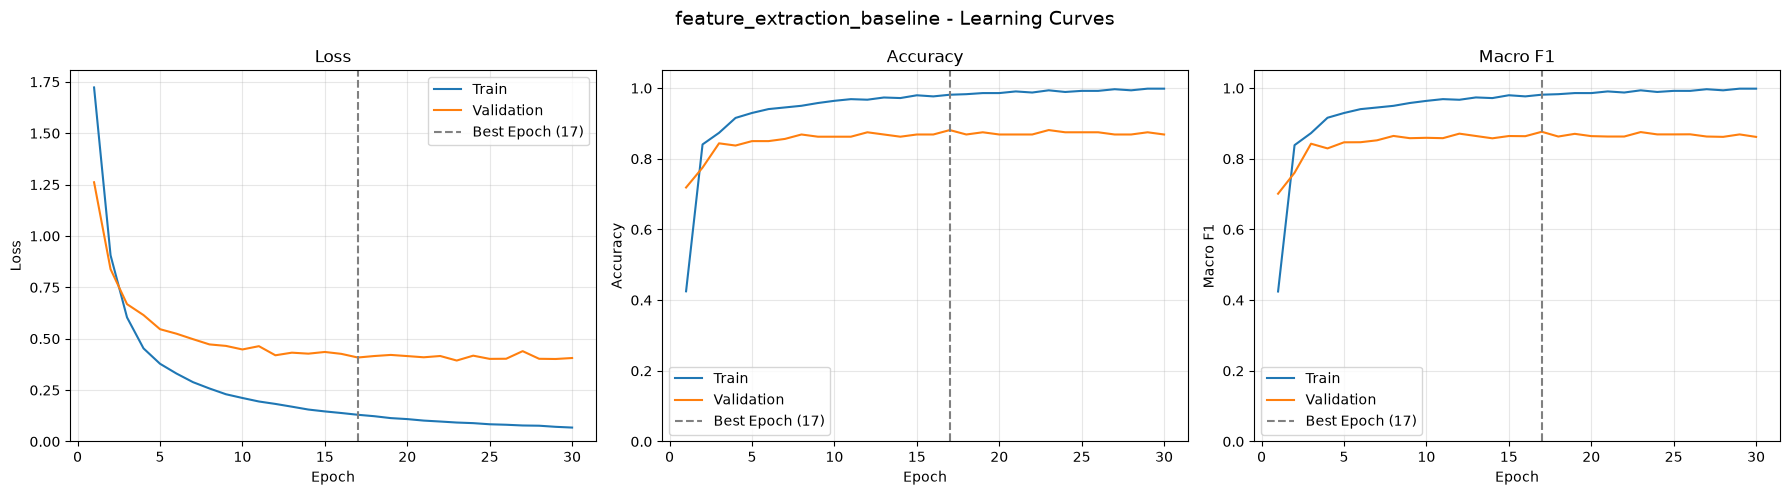

Learning Curves Saved: c:\Users\yunha\human-action-classification\figures\feature_extraction_baseline_learning_curves.png


In [40]:
plot_learning_curves(
    history_df=history_df,
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR
)

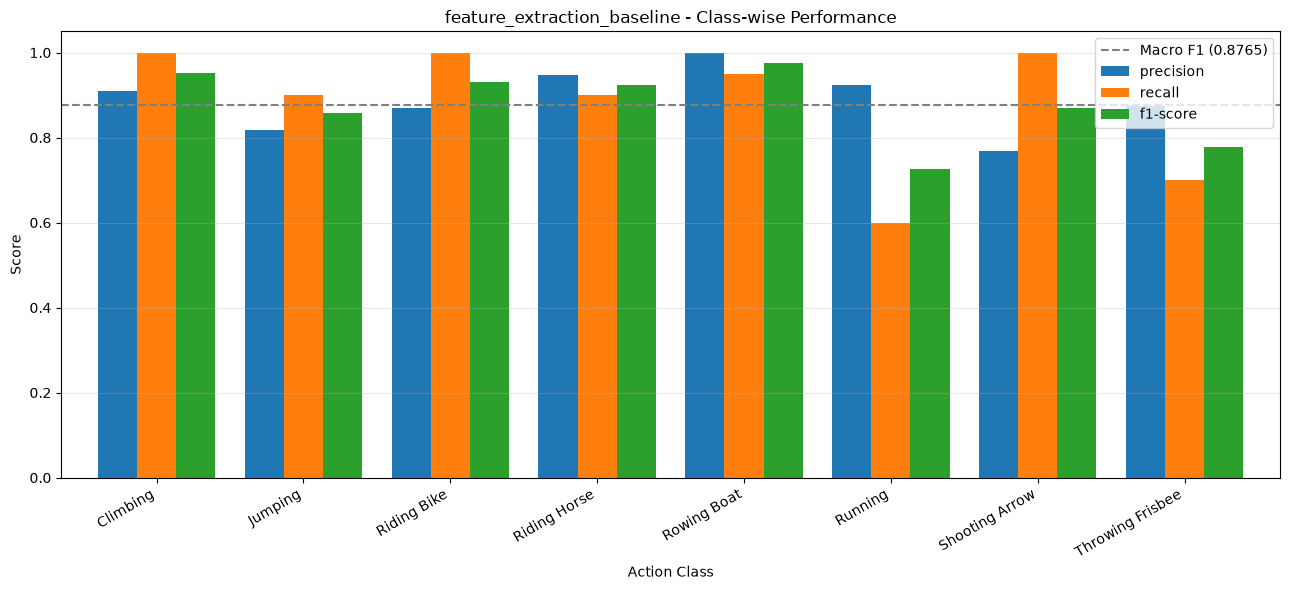

Class Metrics Saved: c:\Users\yunha\human-action-classification\figures\feature_extraction_baseline_class_metrics.png


In [41]:
plot_class_metrics(
    class_report_df=class_analysis["class_report_df"],
    macro_f1=float(best_epoch_result["val_f1"].iloc[0]),
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR
)

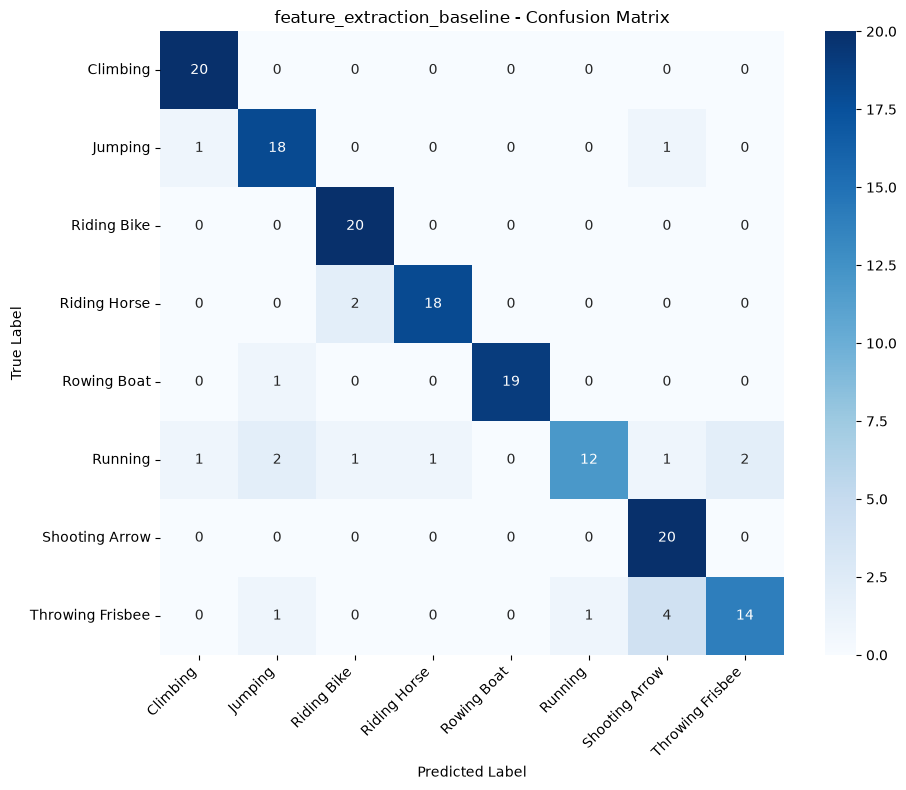

Confusion Matrix Saved: c:\Users\yunha\human-action-classification\figures\feature_extraction_baseline_confusion_matrix.png


In [42]:
plot_confusion_matrix(
    cm_df=class_analysis["cm_df"],
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR,
    normalize=False,
    vmax=20
)

## 8. 결과 해석

### 8-1. 전체 분류 성능

Feature Extraction 기준선은 17 Epoch에서 최고 Validation Macro F1 0.8765를 기록하였다.

Scratch 기준선의 Macro F1 0.5837 대비 약 29.28%p 향상되었으며, Accuracy는 0.5875에서 0.8813으로 개선되었다. Validation 오분류 이미지 수는 66장에서 19장으로 감소하였다.

제한된 학습 데이터 환경에서 ImageNet 사전학습 특징을 활용하고 분류기만 학습하는 전략이 효과적임을 확인하였다.

### 8-2. 학습 곡선 및 과적합

학습 초기 Train과 Validation 성능이 빠르게 상승하였으며, Scratch 대비 빠른 수렴 양상을 보였다.

Best Epoch 기준 Train과 Validation Macro F1의 격차는 Scratch의 0.4163에서 Feature Extraction의 0.1049로 감소하였다.

다만 학습 후반부에는 Train 성능이 지속적으로 개선되는 반면 Validation 성능은 정체되는 모습을 보여 과적합 가능성이 완전히 해소된 것은 아니라고 판단하였다.

### 8-3. 클래스별 성능

전체 8개 클래스에서 Scratch 대비 F1-score가 향상되었다.

특히 Riding Horse와 Shooting Arrow의 F1-score가 각각 0.3529에서 0.9231, 0.3902에서 0.8696으로 크게 개선되었다.

반면 Running과 Throwing Frisbee는 각각 0.7273과 0.7778의 F1-score를 기록하여 상대적으로 낮은 성능을 보였다.

Running은 Precision 0.9231에 비해 Recall이 0.6000으로 낮아 실제 Running 이미지를 다른 행동으로 분류하는 문제가 주요 오류로 나타났다.

### 8-4. 주요 혼동 패턴

전체 오분류 19건 중 Running에서 8건, Throwing Frisbee에서 6건이 발생하였다. 두 클래스의 오류는 전체 오분류의 약 73.68%를 차지하였다.

Scratch에서 관찰된 Shooting Arrow와 Throwing Frisbee 간 상호 혼동은 10건에서 4건으로 감소하였으며, Jumping과 Running 간 상호 혼동은 9건에서 2건으로 감소하였다.

다만 일부 혼동 패턴이 여전히 존재하므로 자세 유사성, 운동 도구의 가시성, 촬영 각도 및 배경 의존성 등을 향후 오류 분석의 가설로 설정하였다.

### 8-5. 학습 효율

학습 가능 파라미터 수는 11,180,616개에서 4,104개로 약 99.96% 감소하였다.

전체 학습 시간은 99.90초에서 73.02초로 약 26.91% 단축되었다.

백본의 가중치 업데이트 및 역전파가 제한되더라도 이미지 로딩과 백본의 Forward 연산은 여전히 필요하므로 학습 가능 파라미터 감소율과 실제 학습 시간 감소율에는 차이가 존재한다.

### 8-6. 종합 판단 및 향후 계획

Feature Extraction은 공통 기준선 설정에서 Scratch 대비 분류 성능, 과적합 완화 및 학습 효율 측면에서 개선된 결과를 보였다.

다만 단일 Random Seed와 제한된 Validation 데이터에 기반한 결과이며, 사전학습 가중치와 백본 동결의 개별 효과를 분리하여 검증한 것은 아니다.

이후 Full Fine-tuning 기준선을 구축하여 백본까지 학습하는 것이 추가적인 성능 개선으로 이어지는지 확인한다.

세 가지 학습 전략의 기준선을 확보한 후 학습 곡선, 클래스별 성능 및 오류 패턴을 종합적으로 비교하고 기본 튜닝과 오류 분석 기반 개선 실험을 수행할 예정이다.

Test 데이터는 최종 모델 및 실험 설정 확정 전까지 평가에 사용하지 않는다.